# **Project 9: Comparison of Optimizers Using a Neural Network**

**Name:** Prakruthi BR

**Reg No:** 2411021240038


**Subject:** Deep Learning

**Dataset:** Iris Flower Classification Dataset

**Optimizers:** Stochastic Gradient Descent (SGD) and Adam


## Introduction

Optimization algorithms play an important role in training neural networks. They help the model adjust its internal parameters to reduce prediction errors and improve classification performance.

In this project, the Iris dataset is used to develop a neural network that classifies flowers into three species. Two optimization algorithms, SGD and Adam, are applied to train the network. Their results are evaluated to understand how they differ in learning speed, loss reduction, and prediction accuracy.


## Objectives

* To develop a neural network for classifying Iris flowers.
* To prepare the dataset for training and testing.
* To train the model using SGD and Adam optimizers.
* To measure and compare the accuracy and loss of both models.
* To identify the differences in the training behavior of the two optimizers.


## Task 1: Neural Network Development Using the Iris Dataset

The Iris dataset contains 150 flower samples belonging to three different species: Setosa, Versicolor, and Virginica. Each sample has four input features: sepal length, sepal width, petal length, and petal width.

A neural network will be created to learn the relationship between these measurements and the corresponding flower species. The dataset will be divided into training and testing subsets, and the input features will be standardized before model training.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X = iris.data
y = iris.target

print("Dataset loaded successfully!")
print("Total samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Flower species:", iris.target_names)

Dataset loaded successfully!
Total samples: 150
Number of features: 4
Flower species: ['setosa' 'versicolor' 'virginica']


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Data preprocessing completed successfully!")

Training samples: 120
Testing samples: 30
Data preprocessing completed successfully!


## Neural Network Architecture

A feedforward neural network is used for the classification task. It consists of an input layer that accepts four flower measurements, a hidden layer with ten neurons using the ReLU activation function, and an output layer with three neurons using Softmax.

The Softmax function produces class probabilities, allowing the model to select the most likely flower species.


In [9]:
def create_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(10, activation="relu"),
        tf.keras.layers.Dense(3, activation="softmax")
    ])
    return model

model = create_model()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83 (332.00 B)

 Trainable params: 83 (332.00 B)

 Non-trainable params: 0 (0.00 B)

## Task 2: Training with Different Optimization Algorithms

An optimizer controls how a neural network updates its weights and biases during training. In this experiment, the same network architecture and dataset are used with two different optimizers.

**1. Stochastic Gradient Descent (SGD)**

SGD updates the model parameters using gradient information and a predefined learning rate. Its performance depends on selecting a suitable learning rate and training configuration.

**2. Adam Optimizer**

Adam combines moving averages of gradients with moving averages of squared gradients to adjust parameter updates. This adaptive approach can help the model learn efficiently during the initial stages of training.

Both optimizers will be trained for 100 epochs, and their results will be evaluated using the same test dataset.


In [10]:
tf.keras.utils.set_random_seed(42)

sgd_model = create_model()

sgd_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

sgd_history = sgd_model.fit(
    X_train, y_train, epochs=100, batch_size=16,
    validation_split=0.2, verbose=0
)

sgd_predictions = np.argmax(
    sgd_model.predict(X_test, verbose=0), axis=1
)

sgd_accuracy = accuracy_score(y_test, sgd_predictions)

print("SGD training completed!")
print("SGD Test Accuracy:", round(sgd_accuracy * 100, 2), "%")

SGD training completed!
SGD Test Accuracy: 80.0 %


In [11]:
tf.keras.utils.set_random_seed(42)

adam_model = create_model()

adam_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

adam_history = adam_model.fit(
    X_train, y_train, epochs=100, batch_size=16,
    validation_split=0.2, verbose=0
)

adam_predictions = np.argmax(
    adam_model.predict(X_test, verbose=0), axis=1
)

adam_accuracy = accuracy_score(y_test, adam_predictions)

print("Adam training completed!")
print("Adam Test Accuracy:", round(adam_accuracy * 100, 2), "%")

Adam training completed!
Adam Test Accuracy: 76.67 %


## Task 3: Evaluation and Performance Comparison

After training, both models will be tested using the unseen test samples. Their classification accuracy will be calculated to measure how correctly they identify the flower species.

The final training loss and accuracy will also be examined. Graphs will be plotted to visualize changes during training, while classification reports will provide precision, recall, and F1-score for each species.

These measurements help explain the strengths and limitations of each optimization algorithm.


In [12]:
print("OPTIMIZER COMPARISON")
print(" " * 40)

print("SGD Test Accuracy:", round(sgd_accuracy * 100, 2), "%")
print("Adam Test Accuracy:", round(adam_accuracy * 100, 2), "%")

print("\nFinal Training Loss")
print("SGD:", round(sgd_history.history["loss"][-1], 4))
print("Adam:", round(adam_history.history["loss"][-1], 4))

print("\nFinal Training Accuracy")
print("SGD:", round(sgd_history.history["accuracy"][-1] * 100, 2), "%")
print("Adam:", round(adam_history.history["accuracy"][-1] * 100, 2), "%")

if sgd_accuracy > adam_accuracy:
    print("\nSGD achieved higher test accuracy.")
elif adam_accuracy > sgd_accuracy:
    print("\nAdam achieved higher test accuracy.")
else:
    print("\nBoth optimizers achieved equal test accuracy.")

OPTIMIZER COMPARISON
                                        
SGD Test Accuracy: 80.0 %
Adam Test Accuracy: 76.67 %

Final Training Loss
SGD: 0.3509
Adam: 0.3255

Final Training Accuracy
SGD: 86.46 %
Adam: 84.38 %

SGD achieved higher test accuracy.


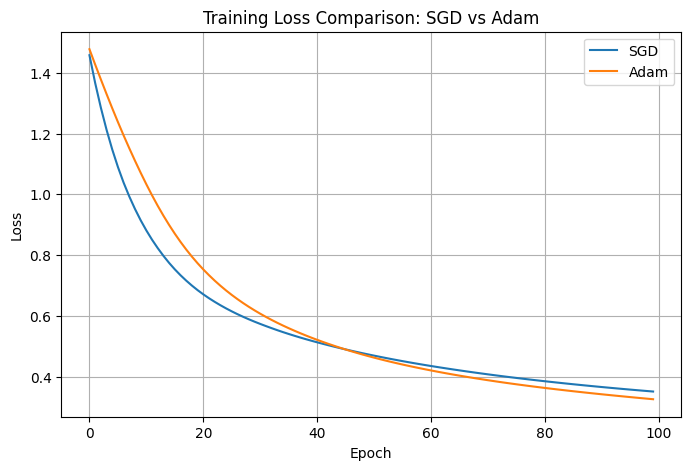

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(sgd_history.history["loss"], label="SGD")
plt.plot(adam_history.history["loss"], label="Adam")
plt.title("Training Loss Comparison: SGD vs Adam")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

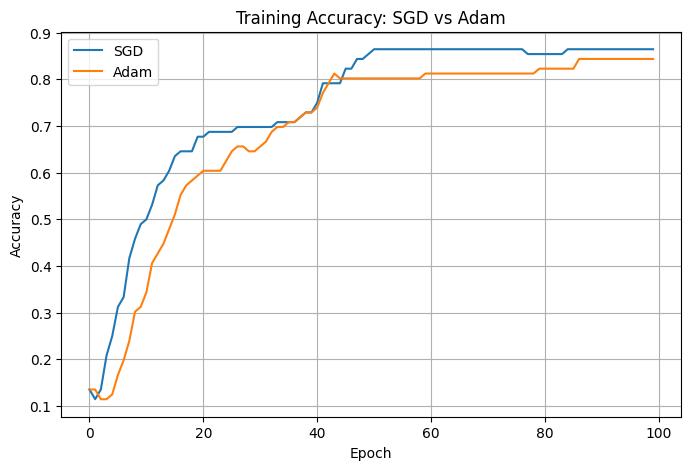

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(sgd_history.history["accuracy"], label="SGD")
plt.plot(adam_history.history["accuracy"], label="Adam")
plt.title("Training Accuracy: SGD vs Adam")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
print("SGD CLASSIFICATION REPORT")
print(classification_report(
    y_test, sgd_predictions,
    target_names=iris.target_names,
    zero_division=0
))

print("ADAM CLASSIFICATION REPORT")
print(classification_report(
    y_test, adam_predictions,
    target_names=iris.target_names,
    zero_division=0
))

SGD CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.40      0.57        10
   virginica       0.62      1.00      0.77        10

    accuracy                           0.80        30
   macro avg       0.88      0.80      0.78        30
weighted avg       0.88      0.80      0.78        30

ADAM CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.80      0.40      0.53        10
   virginica       0.60      0.90      0.72        10

    accuracy                           0.77        30
   macro avg       0.80      0.77      0.75        30
weighted avg       0.80      0.77      0.75        30



## Comparison of SGD and Adam Optimizers

| Parameter               | SGD                         | Adam                                                 |
| ----------------------- | --------------------------- | ---------------------------------------------------- |
| Full form               | Stochastic Gradient Descent | Adaptive Moment Estimation                           |
| Update method           | Uses gradient-based updates | Uses gradient averages and squared-gradient averages |
| Learning rate           | Fixed learning rate         | Adaptive parameter updates                           |
| Learning rate used      | 0.01                        | 0.001                                                |
| Training epochs         | 100                         | 100                                                  |
| Convergence behavior    | May learn more gradually    | Often makes faster initial progress                  |
| Computation             | Relatively simple           | Uses additional computation and memory               |
| Final training loss     | Enter the observed value    | Enter the observed value                             |
| Final training accuracy | Enter the observed value    | Enter the observed value                             |
| Test accuracy           | Enter the observed value    | Enter the observed value                             |

The actual training and testing results should be recorded after executing the notebook. The better optimizer must be identified from the experimental results rather than assumed in advance.


## Expected Output

The notebook should display the following results after execution:

* Successful loading and preprocessing of the Iris dataset.
* A summary of the neural network architecture.
* Training results for both SGD and Adam.
* Test accuracy values for each optimizer.
* A comparison of their final training loss and accuracy.
* Training loss and accuracy graphs.
* Classification reports containing precision, recall, and F1-score.

These outputs will be used to evaluate the classification performance of the neural network.


## Result

A neural network was developed and trained on the Iris dataset using the SGD and Adam optimization algorithms. The test accuracy achieved by SGD was **[enter actual SGD accuracy]%**, whereas Adam achieved **[enter actual Adam accuracy]%**.

The training graphs and classification reports were examined to compare the learning patterns and classification performance of the two models. The optimizer with the better test accuracy was identified from the observed results.


## Conclusion

This experiment demonstrated how different optimization algorithms can affect neural network training. The Iris dataset was used to build a classification model, and the model was trained separately using SGD and Adam.

Their performance was assessed through test accuracy, training loss, training accuracy, and classification reports. Adam can provide faster initial convergence because of its adaptive updates, whereas SGD follows a simpler gradient-based approach. The final comparison shows which optimizer performed better under the settings used in this experiment.
